# Email Spam Detection with Machine Learning
**Oasis Infobyte Internship · Data Science · Task 4**

Goal: build an NLP classifier that labels a message as **spam** or **ham** (legitimate).

Dataset: the **SMS Spam Collection** (UCI / Kaggle), 5,574 English messages labelled ham or spam,
saved in `data/spam.csv` with columns `label` and `message`.

Steps: load data → class distribution → text preprocessing → TF-IDF features → train/test split →
Multinomial Naive Bayes + Logistic Regression + Linear SVM → evaluation → why recall matters → word clouds.

In [1]:
import re
import string
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.stem import PorterStemmer                      # stemming (no extra download needed)
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

In [2]:
df = pd.read_csv("data/spam.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
df.head()

Shape: (5574, 2)
Missing values:
 label      0
message    0
dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Remove exact duplicate messages so the same text cannot appear in both train and test
before = len(df)
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate messages -> {len(df)} remain")

Dropped 403 duplicate messages -> 5171 remain


## 2. Class distribution

       count  percent
label                
ham     4518    87.37
spam     653    12.63


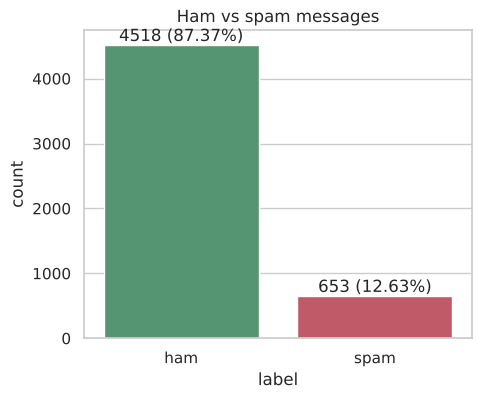

In [4]:
counts = df["label"].value_counts()
dist = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})
print(dist)

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="label", hue="label", palette={"ham": "#4C9F70", "spam": "#D1495B"}, ax=ax, legend=False)
for p, pct in zip(ax.patches, dist.loc[["ham", "spam"], "percent"]):
    ax.annotate(f"{int(p.get_height())} ({pct}%)", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Ham vs spam messages")
fig.savefig(OUT / "class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

The data is **imbalanced**: about 87% ham and 13% spam. A model that always says "ham" would already
score ~87% accuracy, so accuracy alone is misleading; precision, recall and F1 for the spam class matter more.

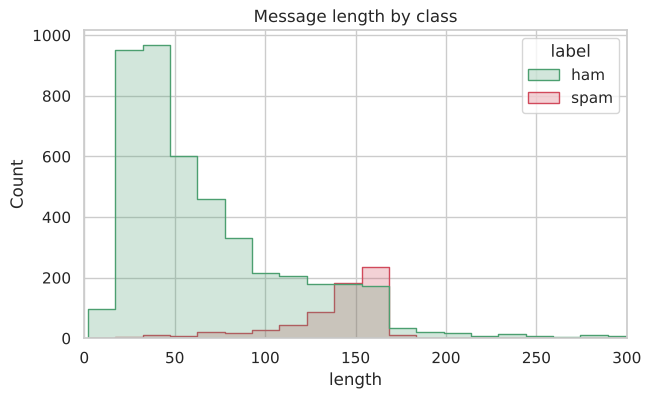

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4518.0,70.9,56.6,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.7,29.8,13.0,132.0,148.0,157.0,223.0


In [5]:
# Spam messages tend to be longer
df["length"] = df["message"].str.len()
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="length", hue="label", bins=60, palette={"ham": "#4C9F70", "spam": "#D1495B"}, element="step")
plt.xlim(0, 300)
plt.title("Message length by class")
plt.savefig(OUT / "message_length.png", dpi=120, bbox_inches="tight")
plt.show()
df.groupby("label")["length"].describe().round(1)

## 3. Text preprocessing pipeline
For every message:
1. **Lowercase** the text.
2. Replace URLs, email addresses and phone/long numbers with placeholder tokens (`urltoken`,
   `emailtoken`, `numtoken`); these patterns are strong spam signals and keeping a shared token is
   more useful than thousands of unique numbers.
3. **Remove punctuation** and remaining digits.
4. **Remove stopwords** (scikit-learn's English stopword list, 318 words such as "the", "and", "is").
5. **Stem** each word with NLTK's Porter stemmer ("winning", "wins" → "win").

In [6]:
stemmer = PorterStemmer()
STOPWORDS = set(ENGLISH_STOP_WORDS)

def preprocess(text: str) -> str:
    text = text.lower()
    text = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", text)
    text = re.sub(r"\S+@\S+", " emailtoken ", text)
    text = re.sub(r"\d{5,}", " numtoken ", text)                      # phone numbers / short codes
    text = text.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))
    text = re.sub(r"\d+", " ", text)
    tokens = [stemmer.stem(w) for w in text.split() if w not in STOPWORDS and len(w) > 1]
    return " ".join(tokens)

df["clean"] = df["message"].apply(preprocess)
df[["message", "clean"]].head(8)

,message,clean
0,"Go until jurong point, crazy.. Available only ...",jurong point crazi avail bugi great world la b...
1,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st t...
3,U dun say so early hor... U c already then say...,dun say earli hor say
4,"Nah I don't think he goes to usf, he lives aro...",nah don think goe usf live
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week word like fun tb ok xxx ...
6,Even my brother is not like to speak with me. ...,brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,request mell mell oru minnaminungint nurungu v...


## 4. Feature extraction with TF-IDF

**What TF-IDF measures:** TF-IDF (Term Frequency × Inverse Document Frequency) scores how important a
word is to *one* message relative to the *whole* collection.

- **Term Frequency (TF):** how often the word appears in this message. More occurrences → more important
  to this message.
- **Inverse Document Frequency (IDF):** `log(N / df(t))`, where N is the number of messages and df(t) is
  the number of messages containing the word. Words that appear almost everywhere ("call", "go") get a
  low IDF; rare words ("prize", "claim") get a high IDF.
- **TF-IDF = TF × IDF**, so a word scores high when it is frequent in this message but rare overall.

Each message becomes a vector of TF-IDF scores (one column per vocabulary term), and each vector is
L2-normalised so long and short messages are comparable. Unlike raw word counts, TF-IDF down-weights
filler words and highlights the distinctive ones, which is exactly what separates spam ("free", "win",
"claim", "urgent") from everyday ham. We also include **bigrams** (two-word phrases such as
"free entry") to capture short phrases.

The vectorizer is fitted on the **training set only** so no information from the test set leaks into
the vocabulary or IDF weights.

## 5. Train/test split (80/20, stratified)

In [7]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)
X_test = tfidf.transform(X_test_txt)
print("Train matrix:", X_train.shape, " Test matrix:", X_test.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Train matrix: (4136, 5174)  Test matrix: (1035, 5174)
Vocabulary size: 5174


In [8]:
# Highest-IDF and lowest-IDF terms, to show the weighting in action
idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("Most common (lowest IDF):", list(idf.head(10).index))
print("Rarest (highest IDF):    ", list(idf.tail(10).index))

Most common (lowest IDF): ['numtoken', 'just', 'ur', 'come', 'ok', 'know', 'want', 'day', 'gt', 'lt']
Rarest (highest IDF):     ['aburo enjoy', 'accept day', 'hope fine', 'hope goe', 'hope great', 'hope like', 'hope text', 'zoe', 'yiju meet', 'yf']


## 6. Train classifiers
- **Multinomial Naive Bayes:** the classic text baseline; fast and works well with TF-IDF features.
- **Logistic Regression:** a linear model with `class_weight="balanced"` to offset the class imbalance.
- **Linear SVM:** a maximum-margin linear classifier, usually the strongest on sparse text features.

In [9]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=10, class_weight="balanced"),
    "Linear SVM": LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, p),
        "precision_spam": precision_score(y_test, p, pos_label="spam"),
        "recall_spam": recall_score(y_test, p, pos_label="spam"),
        "f1_spam": f1_score(y_test, p, pos_label="spam"),
    })

results = pd.DataFrame(rows).sort_values("f1_spam", ascending=False).reset_index(drop=True)
results.to_csv(OUT / "model_comparison.csv", index=False)
results.round(4)

,model,accuracy,precision_spam,recall_spam,f1_spam
0,Multinomial Naive Bayes,0.9884,0.9612,0.9466,0.9538
1,Linear SVM,0.9874,0.9538,0.9466,0.9502
2,Logistic Regression,0.9865,0.9466,0.9466,0.9466


## 7. Evaluation: confusion matrices and classification reports

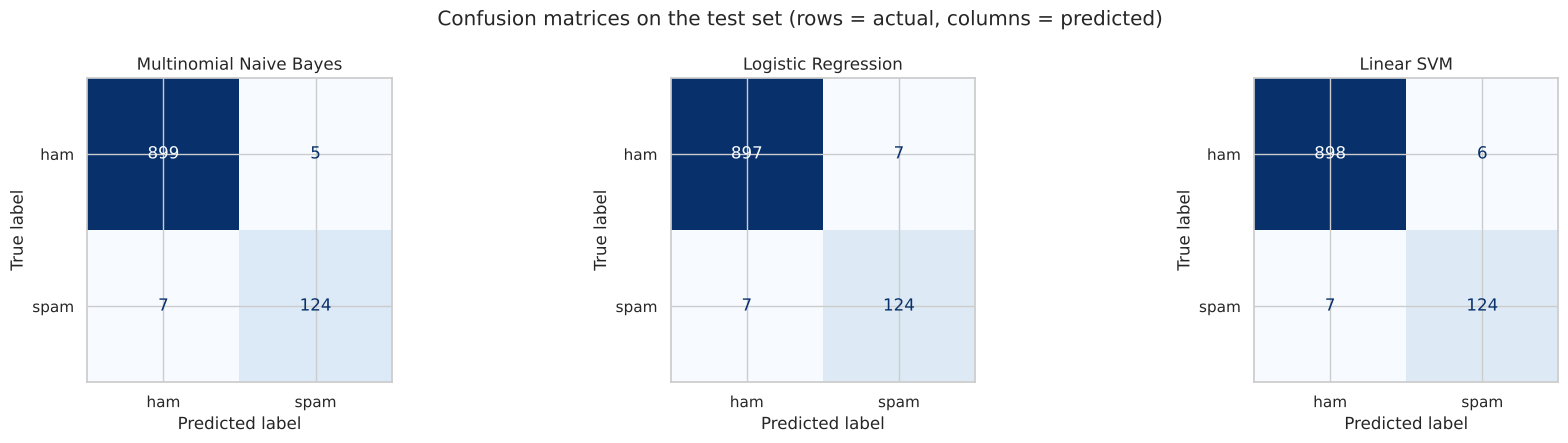

In [10]:
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 4.5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
fig.suptitle("Confusion matrices on the test set (rows = actual, columns = predicted)")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

In [11]:
reports = []
for name in models:
    r = classification_report(y_test, preds[name], digits=3)
    print(f"===== {name} =====\n{r}")
    reports.append(f"===== {name} =====\n{r}")
(OUT / "classification_reports.txt").write_text("\n".join(reports))

===== Multinomial Naive Bayes =====
              precision    recall  f1-score   support

         ham      0.992     0.994     0.993       904
        spam      0.961     0.947     0.954       131

    accuracy                          0.988      1035
   macro avg      0.977     0.971     0.974      1035
weighted avg      0.988     0.988     0.988      1035

===== Logistic Regression =====
              precision    recall  f1-score   support

         ham      0.992     0.992     0.992       904
        spam      0.947     0.947     0.947       131

    accuracy                          0.986      1035
   macro avg      0.969     0.969     0.969      1035
weighted avg      0.986     0.986     0.986      1035

===== Linear SVM =====
              precision    recall  f1-score   support

         ham      0.992     0.993     0.993       904
        spam      0.954     0.947     0.950       131

    accuracy                          0.987      1035
   macro avg      0.973     0.970    

1071

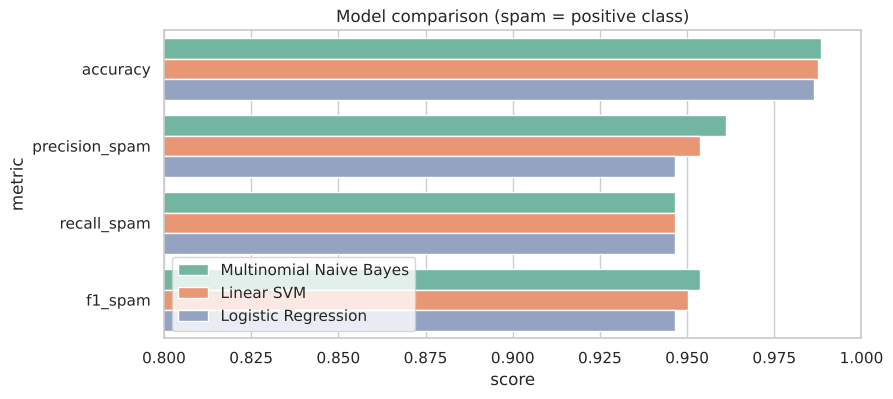

In [12]:
plot_df = results.melt(id_vars="model", var_name="metric", value_name="score")
plt.figure(figsize=(9, 4))
sns.barplot(data=plot_df, x="score", y="metric", hue="model", palette="Set2")
plt.xlim(0.8, 1.0)
plt.title("Model comparison (spam = positive class)")
plt.legend(loc="lower left")
plt.savefig(OUT / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Why is recall especially important for spam detection?

**Recall (for the spam class) = spam messages caught / all spam messages.** It answers: *of all the
spam that actually arrived, how much did the filter catch?*

- Every spam message the model misses (a **false negative**) lands in the user's inbox. Spam is not just
  annoying: it is the main delivery route for **phishing links, scams and malware**, so a single missed
  message can lead to a stolen password or lost money. High recall minimises that exposure.
- Spam is the minority class (~13% here). A lazy model can reach high *accuracy* while missing a large
  share of spam, and only recall exposes that failure.

Recall cannot be the *only* goal, though. Pushing recall to 100% by flagging everything would bury real
messages (false positives, measured by **precision**), and a lost legitimate message, such as a bank OTP
or a job offer, is also costly. That is why we report **F1** (the balance of the two) and choose the model
with the best trade-off, while keeping spam recall high.

## 9. Best model

In [13]:
best = results.iloc[0]
print(f"Best model by spam F1: {best['model']}")
print(results.iloc[[0]].round(4).to_string(index=False))

Best model by spam F1: Multinomial Naive Bayes
                  model  accuracy  precision_spam  recall_spam  f1_spam
Multinomial Naive Bayes    0.9884          0.9612       0.9466   0.9538


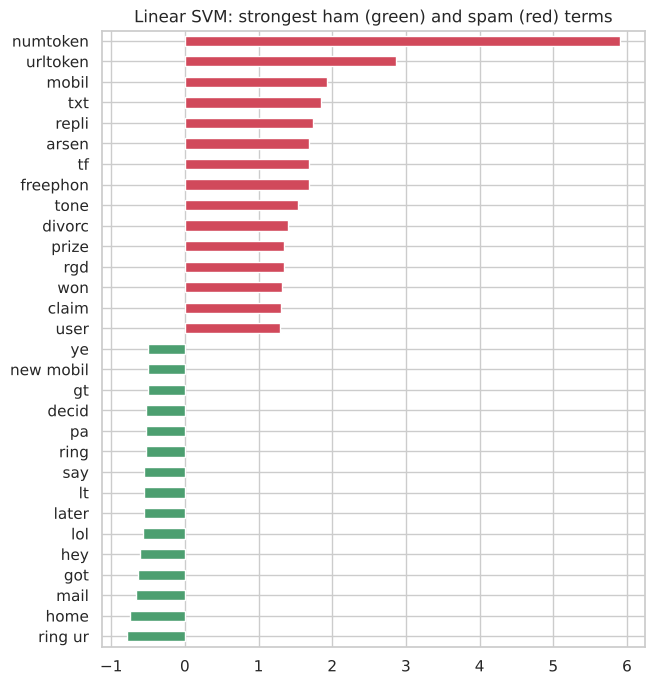

In [14]:
# Most spam-indicative terms according to the Linear SVM's weights
svm = models["Linear SVM"]
coef = pd.Series(svm.coef_[0], index=tfidf.get_feature_names_out())   # positive = pushes towards "spam"
top = pd.concat([coef.nlargest(15), coef.nsmallest(15)]).sort_values()
plt.figure(figsize=(7, 8))
top.plot.barh(color=["#4C9F70" if v < 0 else "#D1495B" for v in top])
plt.title("Linear SVM: strongest ham (green) and spam (red) terms")
plt.savefig(OUT / "top_terms.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
# Try the best model on new messages
best_model = models[best["model"]]
samples = [
    "Congratulations! You have WON a free iPhone. Call 09061701461 now to claim your prize",
    "Hey, are we still meeting for lunch tomorrow at 1?",
    "URGENT: your account has been suspended. Verify at www.secure-bank-login.com",
    "Can you send me the notes from today's class?",
]
for s, p in zip(samples, best_model.predict(tfidf.transform([preprocess(s) for s in samples]))):
    print(f"[{p.upper():4}] {s}")

[SPAM] Congratulations! You have WON a free iPhone. Call 09061701461 now to claim your prize
[HAM ] Hey, are we still meeting for lunch tomorrow at 1?
[SPAM] URGENT: your account has been suspended. Verify at www.secure-bank-login.com
[HAM ] Can you send me the notes from today's class?


## 10. Bonus: word clouds for spam and ham

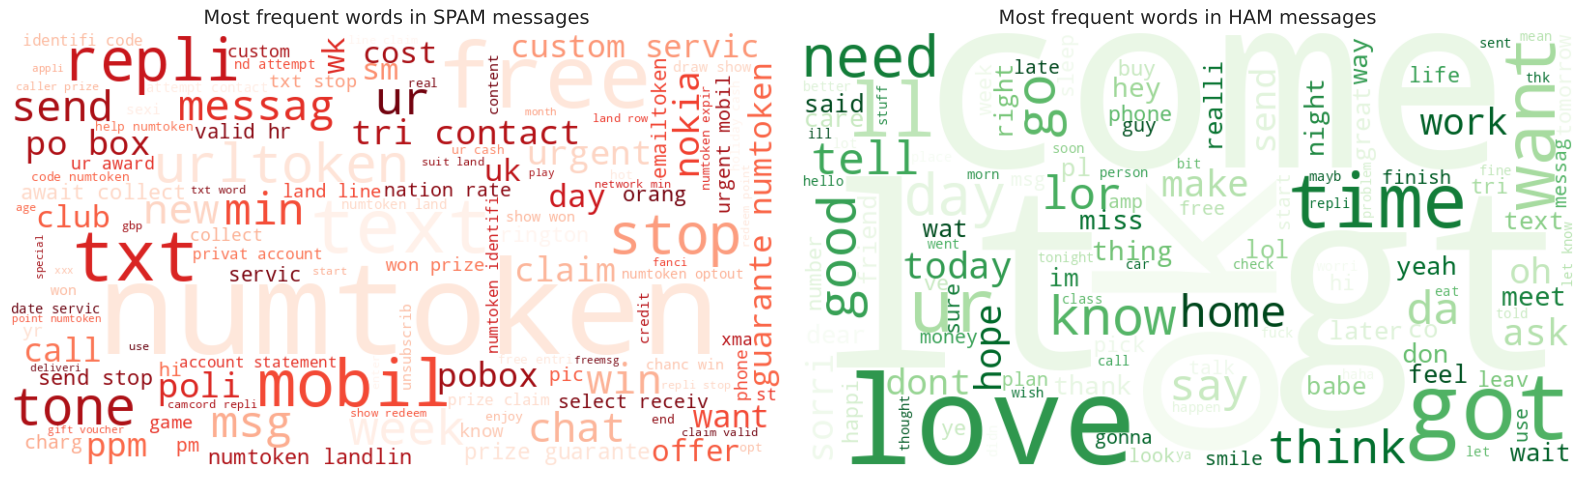

In [16]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label, cmap in zip(axes, ["spam", "ham"], ["Reds", "Greens"]):
    text = " ".join(df.loc[df["label"] == label, "clean"])
    wc = WordCloud(width=800, height=450, background_color="white", colormap=cmap,
                   max_words=120, random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Most frequent words in {label.upper()} messages", fontsize=14)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "wordclouds.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusion
- TF-IDF on cleaned, stemmed text with unigrams and bigrams gives strong features for spam detection.
- All three models reach about 98.7–98.8% accuracy on 1,035 unseen messages; the differences are in how
  many spam messages each one catches (recall) versus how many real messages it wrongly flags (precision).
- **Multinomial Naive Bayes is the best model** here: highest spam F1 (≈0.954) and precision (≈0.961) with
  the same spam recall (≈0.947) as the others, and it is the simplest and fastest to train.
- The strongest spam signals are phone numbers/short codes (`numtoken`), links (`urltoken`) and reward or
  call-to-action words ("mobile", "txt", "reply", "prize", "won", "claim"), while ham is conversational
  ("home", "hey", "lol", "later", "got").